# Module 07 worked example: a churn network trained by hand

This notebook runs the whole example: train, read the curves, compare with a baseline, and score two customers. The code is in `train.py`, `churn_data.py`, `churn_net.py` and `predict.py` beside it.

In [1]:
import train

train.main()

epoch   1  train loss 1.1743  val loss 1.1496  val F1 0.291
epoch  10  train loss 0.9749  val loss 0.9488  val F1 0.402


epoch  20  train loss 0.9394  val loss 0.9426  val F1 0.420


epoch  30  train loss 0.9098  val loss 0.9301  val F1 0.404


epoch  40  train loss 0.8866  val loss 0.9389  val F1 0.406
epoch  50  train loss 0.8491  val loss 0.9385  val F1 0.410


epoch  60  train loss 0.8310  val loss 0.9510  val F1 0.424
epoch  70  train loss 0.8048  val loss 0.9674  val F1 0.420


epoch  80  train loss 0.7839  val loss 0.9788  val F1 0.422
Best epoch by validation loss: 33
Test set, used once: {'precision': 0.25, 'recall': 0.544, 'f1': 0.343}
Logistic regression baseline F1: 0.392
Saved churn_net.pt, preprocessor.joblib, history.csv, learning_curves.png, metrics.json


## The learning curves

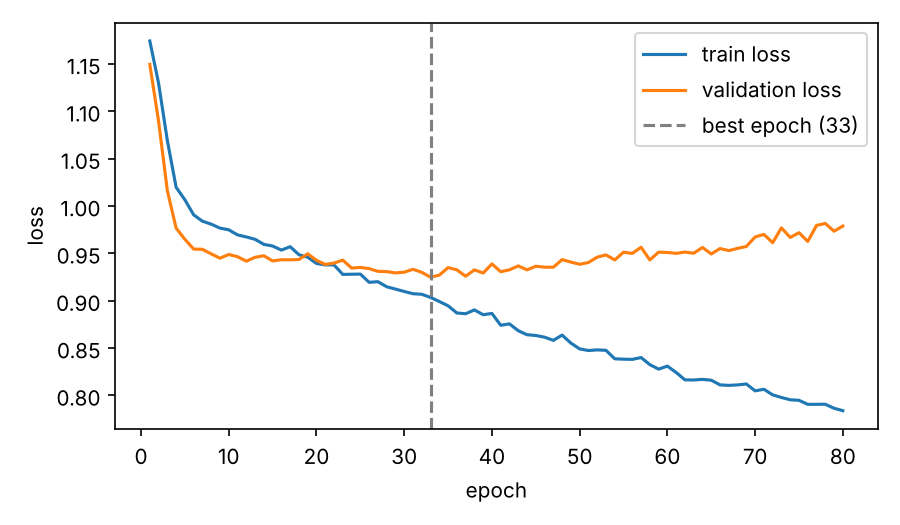

In [2]:
from IPython.display import Image

Image("learning_curves.png")

## Score two customers

The function applies the saved preprocessor first, so a raw customer goes in and a probability comes out.

In [3]:
from predict import predict_churn

print("new, month-to-month, five calls:", round(predict_churn(2, 95.0, 5, "month-to-month", "card"), 3))
print("long-standing, two-year, no calls:", round(predict_churn(60, 40.0, 0, "two-year", "bank transfer"), 3))
print("charge missing:", round(predict_churn(12, float("nan"), 1, "one-year", "card"), 3))

new, month-to-month, five calls: 0.957
long-standing, two-year, no calls: 0.067
charge missing: 0.47


## Your turn

1. Change `hidden` in `ChurnNet` to 4 and to 64 and compare the best validation loss.
2. Find a threshold other than 0.5 that gives a better validation F1. Which split must you use to choose it, and which split must you not use?
3. Add `weight_decay=1e-3` to the Adam optimizer and watch what happens to the gap between the two loss curves.